# OmniGen2 — setup + subject-driven test

**Use a GPU runtime** for the generation cells (Runtime → Change runtime type → L4 or A100).

This notebook is **idempotent**: the install and image-restore cells skip themselves if the work is already done, so re-running won't re-clone, re-install, or re-copy. It restores the extracted image subset from Drive and runs one subject-driven generation (reference photo + instruction → image) on a real test row.

## 1. Setup (skips if already installed)

In [ ]:
import os, subprocess, sys

REPO = "/content/OmniGen2"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "https://github.com/VectorSpaceLab/OmniGen2.git", REPO], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], cwd=REPO, check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "huggingface_hub[hf_xet]>=0.30.0,<1.0"], check=True)
    print("OmniGen2 installed.")
else:
    print("OmniGen2 already present - skipping clone/install.")

OmniGen2 installed.


## 2. Mount Drive, token, paths

In [ ]:
from google.colab import drive, userdata
import os

drive.mount("/content/drive")
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")   # Hugging Face token from Colab secrets

DRIVE = "/content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data"        # Must match the dataset directory used during data preparation.
OUT   = "/content/outputs"
os.makedirs(OUT, exist_ok=True)
print("Data dir:", DRIVE)

Mounted at /content/drive
Data dir: /content/drive/MyDrive/My Master's Thesis/Data


## 3. Restore image subset + splits from Drive (skips if already local)

In [ ]:
import os, subprocess

IMGS = "/content/imgs"
TAR  = f"{DRIVE}/imgs_subset.tar"

def n_files(d):
    return sum(len(f) for _, _, f in os.walk(d)) if os.path.isdir(d) else 0

if n_files(IMGS) == 0:
    assert os.path.exists(TAR), f"Not found: {TAR}  (verify DRIVE path)"
    os.makedirs(IMGS, exist_ok=True)
    print("Restoring image subset from Drive (once per session)...")
    subprocess.run(f'cp "{TAR}" /content/imgs_subset.tar && tar -xf /content/imgs_subset.tar -C {IMGS}', shell=True)
    print("Restored", n_files(IMGS), "images.")
else:
    print("Images already present:", n_files(IMGS), "files.")

# bring the split files local too
for s in ["train", "val", "test"]:
    src = f"{DRIVE}/{s}.jsonl"
    if os.path.exists(src) and not os.path.exists(f"/content/{s}.jsonl"):
        subprocess.run(["cp", src, f"/content/{s}.jsonl"])
print("Splits present:", [s for s in ["train","val","test"] if os.path.exists(f"/content/{s}.jsonl")])

Restoring image subset from Drive (once per session)...
Restored 37063 images.
Splits present: ['train', 'val', 'test']


## 4. Confirm inference flags (cheap - no model load)
Look for the **reference-image flag**, `--image_guidance_scale`, and `--seed`. If they differ from the helper below, adjust it.

In [ ]:
subprocess.run(["python", "inference.py", "--help"], cwd=REPO)

CompletedProcess(args=['python', 'inference.py', '--help'], returncode=0)

## 5. Reusable generation helper
Pass `input_images=[...]` (on-disk paths) for subject-driven generation, or leave it `None` for plain text-to-image. **Adjust the flag names here if the `--help` output above differs.** Note: `inference.py` reloads the model on every call (a few minutes each) - fine for single tests; the batch harness later will load the model once instead.

In [ ]:
import subprocess, os

def generate(instruction, input_images=None, out_name="out.png",
             steps=20, text_g=4.0, image_g=2.0, seed=0, size=512, offload=False):
    """input_images: list of on-disk paths -> subject-driven; None -> text-to-image."""
    out_path = os.path.join(OUT, out_name)
    cmd = ["python", "inference.py",
           "--model_path", "OmniGen2/OmniGen2",
           "--num_inference_step", str(steps),
           "--height", str(size), "--width", str(size),
           "--text_guidance_scale", str(text_g),
           "--seed", str(seed),
           "--instruction", instruction,
           "--num_images_per_prompt", "1", "--dtype", "fp16",
           "--output_image_path", out_path]
    if input_images:
        cmd += ["--image_guidance_scale", str(image_g), "--input_image_path", *input_images]
    if offload:
        cmd += ["--enable_model_cpu_offload"]
    print(("subject-driven" if input_images else "text-to-image"), "->", out_path)
    subprocess.run(cmd, cwd=REPO)
    return out_path

## 6. Subject-driven test on one real test row

In [ ]:
import json, os

row   = json.loads(open("/content/test.jsonl", encoding="utf-8").readline())
instr = row["instruction"]
refs  = [os.path.join("/content/imgs", p) for p in row["input_images"]]
print("Instruction:\n", instr)
print("\nReference image(s):", refs)
print("All exist:", all(os.path.exists(r) for r in refs))

generate(instr, input_images=refs, out_name="subject_test.png", seed=0)

Instruction:
 A focused young man sits at a sleek conference table, intently working on a modern laptop that glows softly in front of him. Dressed in a sharp suit, he exudes professionalism and determination, his narrow eyes reflecting a keen intellect. His straight hair is neatly styled, and the slight bags under his eyes hint at long hours spent on important projects. The laptop, a symbol of innovation and connectivity, is adorned with stickers that showcase his personal interests. As he types, the atmosphere is charged with an air of ambition and the drive to succeed in a competitive business landscape. The suit is the one in <img><|image_1|></img>.

Reference image(s): ['/content/imgs/single/input/14/256-mat-0-0_up.png']
All exist: True
subject-driven -> /content/outputs/subject_test.png


'/content/outputs/subject_test.png'

## 7. Display result vs reference

Generated:


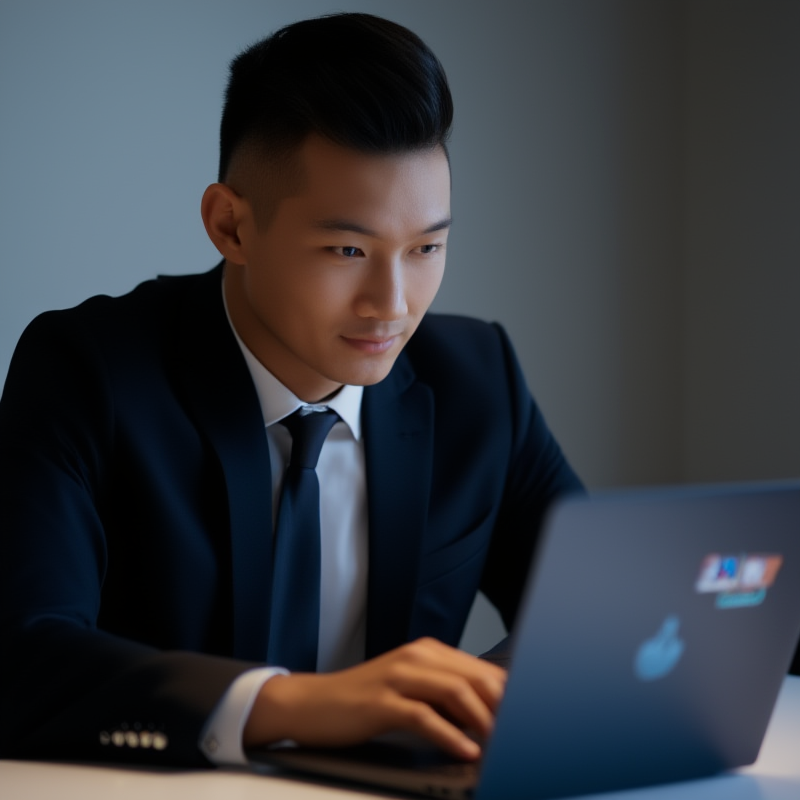

Reference:


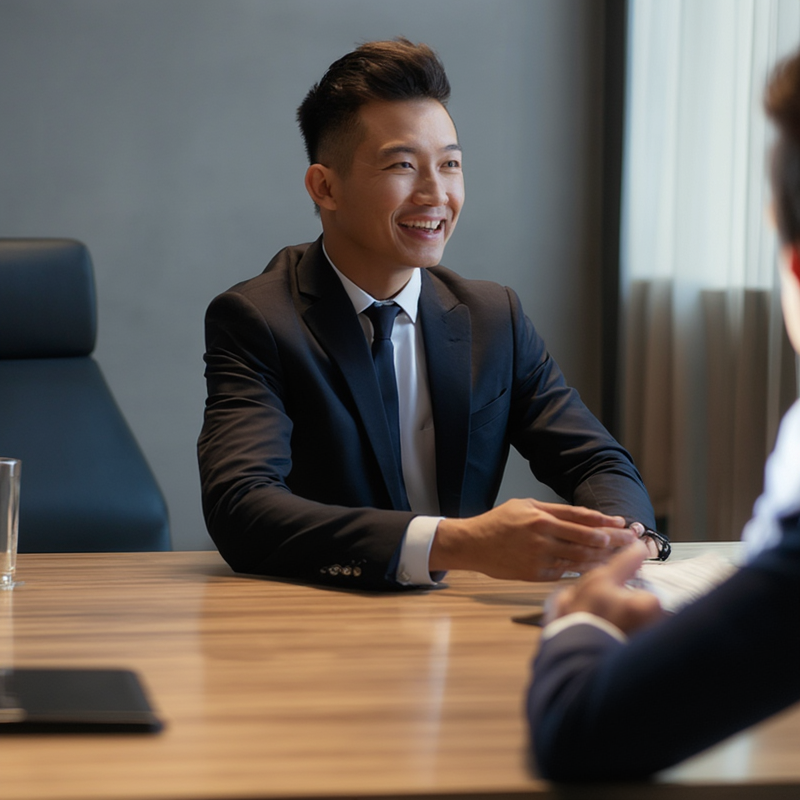

In [ ]:
from PIL import Image
from IPython.display import display

print("Generated:")
display(Image.open(os.path.join(OUT, "subject_test.png")))
print("Reference:")
display(Image.open(refs[0]))

## (Optional) plain text-to-image sanity check
Uncomment to run - no reference image.

text-to-image -> /content/outputs/t2i_test.png


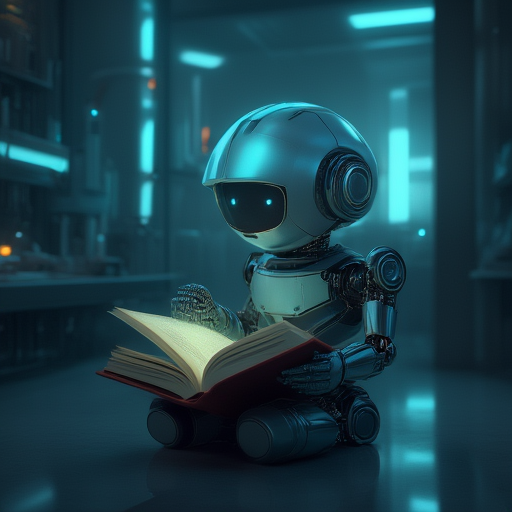

In [ ]:
generate("A small robot reading a book in a clean futuristic laboratory, cinematic lighting, detailed",
         out_name="t2i_test.png")
from PIL import Image; from IPython.display import display
display(Image.open(os.path.join(OUT, "t2i_test.png")))

In [ ]:
!cat /content/OmniGen2/inference.py

import dotenv

dotenv.load_dotenv(override=True)

import argparse
import os
from typing import List, Tuple

from PIL import Image, ImageOps

import torch
from torchvision.transforms.functional import to_pil_image, to_tensor

from accelerate import Accelerator
from diffusers.hooks import apply_group_offloading

from omnigen2.pipelines.omnigen2.pipeline_omnigen2 import OmniGen2Pipeline
from omnigen2.models.transformers.transformer_omnigen2 import OmniGen2Transformer2DModel


def parse_args() -> argparse.Namespace:
    """Parse command line arguments."""
    parser = argparse.ArgumentParser(description="OmniGen2 image generation script.")
    parser.add_argument(
        "--model_path",
        type=str,
        required=True,
        help="Path to model checkpoint.",
    )
    parser.add_argument(
        "--transformer_path",
        type=str,
        default=None,
        help="Path to transformer checkpoint.",
    )
    parser.add_argument(
        "--transformer_lora_path",
        t